In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from IPython.display import Image, display
from langchain_core.runnables.graph import MermaidDrawMethod
from langchain_openai import ChatOpenAI
import os
from pydantic import BaseModel, Field
from typing import List, operator

In [2]:
from dotenv import load_dotenv
load_dotenv()

True

In [3]:
model = ChatOpenAI(
  model_name= 'gpt-4o',
  api_key = os.environ.get('OPENAI_API_KEY')
)

In [4]:
class QuizState(TypedDict):
    topic: str
    content: str
    num_questions: int

    mcqs: Annotated[list, operator.add]
    short_questions: Annotated[list, operator.add]
    true_false: Annotated[list, operator.add]

    final_quiz: str

In [5]:
class MCQ(BaseModel):
    question: str
    options: List[str] = Field(description="Exactly four answer options")
    answer: str

class MCQResponse(BaseModel):
    questions: List[MCQ]

class ShortQuestion(BaseModel):
    question: str
    answer: str

class ShortQuestionResponse(BaseModel):
    questions: List[ShortQuestion]

class TrueFalse(BaseModel):
    statement: str
    answer: bool

class TrueFalseResponse(BaseModel):
    questions: List[TrueFalse]


In [6]:
mcq_model = model.with_structured_output(MCQResponse)
short_question_model = model.with_structured_output(ShortQuestionResponse)
true_false_model = model.with_structured_output(TrueFalseResponse)

In [7]:
def content_creation(state: QuizState)-> QuizState:
  prompt = f"""
  You are an expert educational quiz generator.

  Generate high-quality quiz content based on the following topic:

  Topic: {state['topic']}

  Requirements:
  - Cover the important concepts of the topic.
  - Keep the content factually accurate.
  - Make the content suitable for students.
  - Explain concepts clearly and concisely.
  - Include key facts, definitions, and important relationships.
  - Do not include information unrelated to the topic.
  - Return only the generated educational content."""

  response=model.invoke(prompt)
  return {'content': response.content}

In [8]:
def mcq_genarator(state: QuizState)-> QuizState:


  prompt=f"""
  You are an expert educational quiz generator.

  Generate {state['num_questions']} multiple-choice questions (MCQs) 
  based ONLY on the provided content.

  Topic:
  {state['topic']}

  Content:
  {state['content']}

  Requirements:
  - Each question must have exactly 4 options.
  - Only ONE option should be correct.
  - Questions should test understanding, not just memorization.
  - Keep the questions clear and appropriate for a student.
  - Do not use information that is not present in the content.
  - Make the incorrect options plausible but clearly incorrect.
 - Return the answer for each question.
 - Do not add explanations.

  Output format:
  [
      {{
          "question": "Question text",
          "options": ["Option A", "Option B", "Option C", "Option D"],
          "answer": "Correct option"
      }}
  ]"""

  response=mcq_model.invoke(prompt)
  return {'mcqs': response.questions}

In [9]:
def short_q_genarator(state: QuizState)-> QuizState:
  prompt = f"""
  You are an expert educational question generator.

  Generate short-answer questions based ONLY on the provided content.

  Topic:
  {state['topic']}

  Content:
  {state['content']}

  Requirements:
  - Generate exactly {state['num_questions']} short-answer questions.
  - Questions must be clear, concise, and relevant to the topic.
  - Each question should test understanding of the content.
  - Each question must have a short, accurate answer.
  - Answers should be approximately 1-3 sentences long.
  - Do not include multiple-choice options.
  - Do not use information outside the provided content.
  - Avoid repeating the same question in different words.
  - Return the output in the specified format only.

  Output format:
  [
      {{
          "question": "What is an operating system?",
          "answer": "An operating system manages computer hardware and provides services to application programs."
      }}
  ]
  """

  response = short_question_model.invoke(prompt)
  return{'short_questions':response.questions}

In [10]:
def tf_genarator(state: QuizState)-> QuizState:
  prompt = f"""

  You are an expert educational quiz generator.

  Generate true/false questions based ONLY on the provided content.

  Topic:
  {state['topic']}

  Content:
  {state['content']}

  Requirements:
  - Generate exactly {state['num_questions']} true/false statements.
  - Each statement must be clear, concise, and relevant to the topic.
  - Include a balanced mix of true and false statements.
  - Each statement must test understanding of the provided content.
  - False statements must be factually incorrect based on the content.
  - Do not introduce information that is not present in the content.
  - Avoid ambiguous statements.
  - Do not repeat the same idea in multiple statements.
  - The answer must be a Boolean value: True or False.
  - Return only the output in the specified format.
  - Do not include explanations.

  Output format:
  [
      {{
          "statement": "An operating system manages computer hardware.",
          "answer": true
      }},
      {{
          "statement": "An operating system is used only to design websites.",
          "answer": false
      }}
  ]
  """

  response=true_false_model.invoke(prompt)
  return {'true_false': response.questions}

In [11]:
def combine(state: QuizState)-> QuizState:
  prompt=f"""
  
  You are an expert educational quiz organizer.
  
  Your task is to combine the generated MCQs, short-answer questions, 
  and true/false questions into one well-organized quiz.
  
  Topic:
  {state['topic']}

  MCQs:
  {state['mcqs']}

  Short-Answer Questions:
  {state['short_questions']}

  True/False Questions:
  {state['true_false']}

  Requirements:
  - Combine all questions into one quiz.
  - Organize the quiz into three sections:
    1. Multiple-Choice Questions
    2. Short-Answer Questions
    3. True/False Questions
  - Preserve the original questions, options, and correct answers.
  - Do not generate new questions.
  - Do not remove valid questions.
  - Assign a sequential question number to every question, starting from 1.
  - Keep the question types clearly identified.
  - Maintain the original data for each question.
  - Return the result in the specified format only.

  Return one valid JSON object with a topic and three sections: multiple-choice, short-answer, and true/false. Each section must contain the original questions and answers. Include options for multiple-choice questions, and number all questions sequentially starting from 1.
  """
  response=model.invoke(prompt)
  return{'final_quiz':response.content}

In [12]:
graph=StateGraph(QuizState)

graph.add_node('content_creation',content_creation)
graph.add_node('mcq_genarator',mcq_genarator)
graph.add_node('short_q_genarator',short_q_genarator)
graph.add_node('tf_genarator',tf_genarator)
graph.add_node('combine',combine)

graph.add_edge(START, 'content_creation')
graph.add_edge('content_creation','tf_genarator')
graph.add_edge('content_creation','mcq_genarator')
graph.add_edge('content_creation','short_q_genarator')
graph.add_edge('tf_genarator','combine')
graph.add_edge('mcq_genarator','combine')
graph.add_edge('short_q_genarator','combine')
graph.add_edge('combine',END)

workflow=graph.compile()

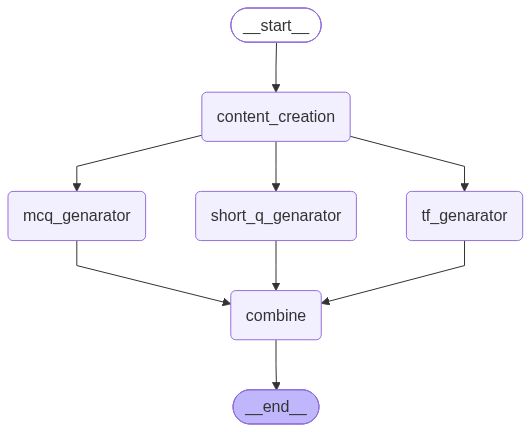

In [13]:
workflow

In [14]:
from IPython.display import Markdown, display

initial = {
    'topic':'Artificial Intelligence',
    'num_questions': 4
}

result = workflow.invoke(initial)
display(Markdown(result['final_quiz']))

```json
{
  "topic": "Artificial Intelligence",
  "sections": {
    "multiple_choice": [
      {
        "number": 1,
        "question": "What distinguishes Machine Learning from traditional AI programming?",
        "options": [
          "A. Machine Learning relies on explicit programming like traditional AI",
          "B. Machine Learning is a completely separate field from AI",
          "C. Machine Learning improves through data without explicit programming",
          "D. Machine Learning does not involve algorithms"
        ],
        "answer": "C"
      },
      {
        "number": 2,
        "question": "Which of the following AI types is still theoretical and not yet achieved?",
        "options": [
          "A. Narrow AI",
          "B. Deep Learning AI",
          "C. General AI",
          "D. Machine Learning AI"
        ],
        "answer": "C"
      },
      {
        "number": 3,
        "question": "Which technology is crucial for AI applications involving human language processing?",
        "options": [
          "A. Neural Networks",
          "B. Natural Language Processing",
          "C. Autonomous Vehicles",
          "D. Recommendation Systems"
        ],
        "answer": "B"
      },
      {
        "number": 4,
        "question": "Which of the following is an ethical concern in AI development?",
        "options": [
          "A. Lack of data",
          "B. Slow processing speeds",
          "C. Inconsistency of outputs",
          "D. Bias in AI systems"
        ],
        "answer": "D"
      }
    ],
    "short_answer": [
      {
        "number": 5,
        "question": "What is the focus of Artificial Intelligence as a field of computer science?",
        "answer": "Artificial Intelligence focuses on creating systems capable of performing tasks that normally require human intelligence, such as reasoning, learning, problem-solving, perception, and language understanding."
      },
      {
        "number": 6,
        "question": "How does Machine Learning enable AI systems to improve?",
        "answer": "Machine Learning enables AI systems to improve by using algorithms and statistical models to learn from data, enhancing performance on specific tasks without explicit programming."
      },
      {
        "number": 7,
        "question": "Why is Deep Learning considered vital in the realm of AI?",
        "answer": "Deep Learning is vital because it uses deep neural networks to achieve higher accuracy in complex tasks like image and speech recognition, which are crucial for advanced AI applications."
      },
      {
        "number": 8,
        "question": "What purpose does Natural Language Processing serve in AI?",
        "answer": "Natural Language Processing serves to facilitate interaction between computers and humans by enabling machines to understand, interpret, and generate human language for tasks such as translation and sentiment analysis."
      }
    ],
    "true_false": [
      {
        "number": 9,
        "statement": "Machine learning is a separate field entirely unrelated to artificial intelligence.",
        "answer": false
      },
      {
        "number": 10,
        "statement": "Deep learning utilizes deep neural networks to improve the accuracy of AI systems.",
        "answer": true
      },
      {
        "number": 11,
        "statement": "Artificial General Intelligence currently performs any intellectual task that a human can.",
        "answer": false
      },
      {
        "number": 12,
        "statement": "Natural Language Processing is an AI method that helps machines understand human language.",
        "answer": true
      }
    ]
  }
}
```